In [27]:
name = "\u0905\u092F\u093E\u0928 \u0916\u093E\u0928"
nameT = "\u0935\u0948\u0936\u093E\u0932\u0940 \u0907\u0902\u0917\u0933\u0947"
print("Checked by : " +nameT)
print("Implement by : "+ name)

Checked by : वैशाली इंगळे
Implement by : अयान खान


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

sns.set_theme(style="whitegrid")

BLUE = "#4C78A8"
ORANGE = "#F28E2B"

print("Libraries imported successfully!")

Libraries imported successfully!


In [29]:
df = pd.read_csv("Admission_Predict.csv")

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (400, 9)


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [30]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe().T)

Column names:
['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         400 non-null    int64  
 1   GRE Score          400 non-null    int64  
 2   TOEFL Score        400 non-null    int64  
 3   University Rating  400 non-null    int64  
 4   SOP                400 non-null    float64
 5   LOR                400 non-null    float64
 6   CGPA               400 non-null    float64
 7   Research           400 non-null    int64  
 8   Chance of Admit    400 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 28.3 KB

Missing values:


,Missing Values
Serial No.,0
GRE Score,0
TOEFL Score,0
University Rating,0
SOP,0
LOR,0
CGPA,0
Research,0
Chance of Admit,0



Duplicate rows: 0

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
Serial No.,400.0,200.500000,115.614301,1.00,100.75,200.50,300.2500,400.00
GRE Score,400.0,316.807500,11.473646,290.00,308.00,317.00,325.0000,340.00
TOEFL Score,400.0,107.410000,6.069514,92.00,103.00,107.00,112.0000,120.00
University Rating,400.0,3.087500,1.143728,1.00,2.00,3.00,4.0000,5.00
SOP,400.0,3.400000,1.006869,1.00,2.50,3.50,4.0000,5.00
LOR,400.0,3.452500,0.898478,1.00,3.00,3.50,4.0000,5.00
CGPA,400.0,8.598925,0.596317,6.80,8.17,8.61,9.0625,9.92
Research,400.0,0.547500,0.498362,0.00,0.00,1.00,1.0000,1.00
Chance of Admit,400.0,0.724350,0.142609,0.34,0.64,0.73,0.8300,0.97


In [31]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove the serial number because it is only an identifier
for col in ["Serial No."]:
    if col in df.columns:
        df = df.drop(columns=col)

# Convert columns to numeric where possible
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Fill missing numeric values with their median
df = df.fillna(df.median(numeric_only=True))

print("Missing values after cleaning:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Cleaned dataset shape:", df.shape)
display(df.head())

Missing values after cleaning:


,Missing Values
GRE Score,0
TOEFL Score,0
University Rating,0
SOP,0
LOR,0
CGPA,0
Research,0
Chance of Admit,0


Cleaned dataset shape: (400, 8)


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,337,118,4,4.5,4.5,9.65,1,0.92
1,324,107,4,4.0,4.5,8.87,1,0.76
2,316,104,3,3.0,3.5,8.00,1,0.72
3,322,110,3,3.5,2.5,8.67,1,0.80
4,314,103,2,2.0,3.0,8.21,0,0.65


In [6]:
target_col = "Chance of Admit"

if target_col not in df.columns:
    raise ValueError("Chance of Admit column not found!")

# Calculate the threshold dynamically
threshold = df[target_col].quantile(0.75)

# Convert continuous values into two classes
df["Admission Class"] = np.where(
    df[target_col] >= threshold,
    "High",
    "Standard"
)

print(f"75th percentile threshold: {threshold:.4f}")

print("\nAdmission class distribution:")
display(df["Admission Class"].value_counts().to_frame("Count"))

75th percentile threshold: 0.8300

Admission class distribution:


,Count
Admission Class,
Standard,299
High,101


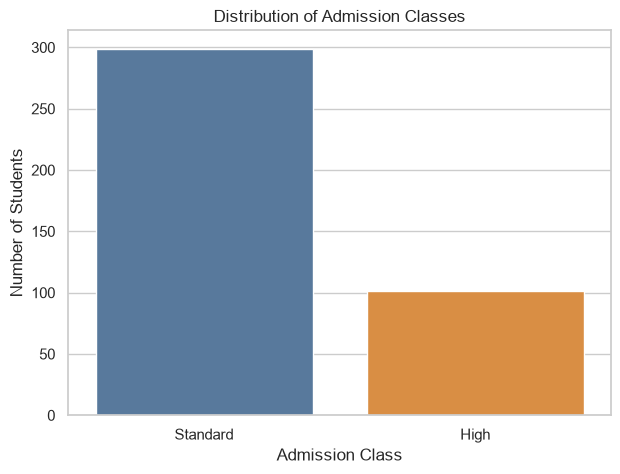

In [7]:
class_counts = df["Admission Class"].value_counts()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    hue=class_counts.index,
    palette={
        "Standard": BLUE,
        "High": ORANGE
    },
    legend=False
)

plt.title("Distribution of Admission Classes")
plt.xlabel("Admission Class")
plt.ylabel("Number of Students")
plt.show()

In [8]:
feature_candidates = [
    col for col in df.columns
    if col not in [target_col, "Admission Class"]
]

outlier_results = []

for col in feature_candidates:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_results.append({
        "Feature": col,
        "Q1 (25%)": q1,
        "Q3 (75%)": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": int(outliers)
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df.round(3))

,Feature,Q1 (25%),Q3 (75%),IQR,Lower Bound,Upper Bound,Outlier Count
0,GRE Score,308.00,325.000,17.000,282.500,350.500,0
1,TOEFL Score,103.00,112.000,9.000,89.500,125.500,0
2,University Rating,2.00,4.000,2.000,-1.000,7.000,0
3,SOP,2.50,4.000,1.500,0.250,6.250,0
4,LOR,3.00,4.000,1.000,1.500,5.500,1
5,CGPA,8.17,9.062,0.893,6.831,10.401,1
6,Research,0.00,1.000,1.000,-1.500,2.500,0


In [9]:
X = df.drop(
    columns=[target_col, "Admission Class"]
)

y = df["Admission Class"].map({
    "Standard": 0,
    "High": 1
})

print("Feature columns:")
print(X.columns.tolist())

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget encoding:")
print("0 = Standard")
print("1 = High")

display(X.head())

Feature columns:
['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']

Features shape: (400, 7)
Target shape: (400,)

Target encoding:
0 = Standard
1 = High


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
0,337,118,4,4.5,4.5,9.65,1
1,324,107,4,4.0,4.5,8.87,1
2,316,104,3,3.0,3.5,8.00,1
3,322,110,3,3.5,2.5,8.67,1
4,314,103,2,2.0,3.0,8.21,0


In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=91,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
display(y_train.value_counts().to_frame("Count"))

print("\nTesting class distribution:")
display(y_test.value_counts().to_frame("Count"))

Training samples: 320
Testing samples: 80

Training class distribution:


,Count
Admission Class,
0,239
1,81



Testing class distribution:


,Count
Admission Class,
0,60
1,20


In [33]:
tree_gini = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    min_samples_split=2,
    min_samples_leaf=3,
    random_state=91
)

tree_entropy = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=4,
    min_samples_split=2,
    min_samples_leaf=3,
    random_state=91
)

print("Gini Decision Tree Parameters:")
display(
    pd.Series(tree_gini.get_params(), name="Value").to_frame()
)

print("Entropy Decision Tree Parameters:")
display(
    pd.Series(tree_entropy.get_params(), name="Value").to_frame()
)

Gini Decision Tree Parameters:


,Value
ccp_alpha,0.0
class_weight,None
criterion,gini
max_depth,4
max_features,None
max_leaf_nodes,None
min_impurity_decrease,0.0
min_samples_leaf,3
min_samples_split,2
min_weight_fraction_leaf,0.0


Entropy Decision Tree Parameters:


,Value
ccp_alpha,0.0
class_weight,None
criterion,entropy
max_depth,4
max_features,None
max_leaf_nodes,None
min_impurity_decrease,0.0
min_samples_leaf,3
min_samples_split,2
min_weight_fraction_leaf,0.0


In [34]:
naive_bayes = GaussianNB(
    var_smoothing=1e-9
)

print("Gaussian Naive Bayes Parameters:")
display(
    pd.Series(
        naive_bayes.get_params(),
        name="Value"
    ).to_frame()
)

Gaussian Naive Bayes Parameters:


,Value
priors,NaN
var_smoothing,1.000000e-09


In [35]:
models = {
    "Decision Tree (Gini)": tree_gini,
    "Decision Tree (Entropy)": tree_entropy,
    "Gaussian Naive Bayes": naive_bayes
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

Decision Tree (Gini) trained successfully!
Decision Tree (Entropy) trained successfully!
Gaussian Naive Bayes trained successfully!


In [36]:
predictions = {}

for name, model in models.items():
    predictions[name] = model.predict(X_test)

print("Predictions generated for all three models.")

Predictions generated for all three models.


In [37]:
metric_rows = []

for name, y_pred in predictions.items():
    metric_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

results = pd.DataFrame(metric_rows).set_index("Model")

display(results.round(4))

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Decision Tree (Gini),0.9375,0.8000,1.00,0.8889
Decision Tree (Entropy),0.9500,0.8636,0.95,0.9048
Gaussian Naive Bayes,0.8875,0.7037,0.95,0.8085


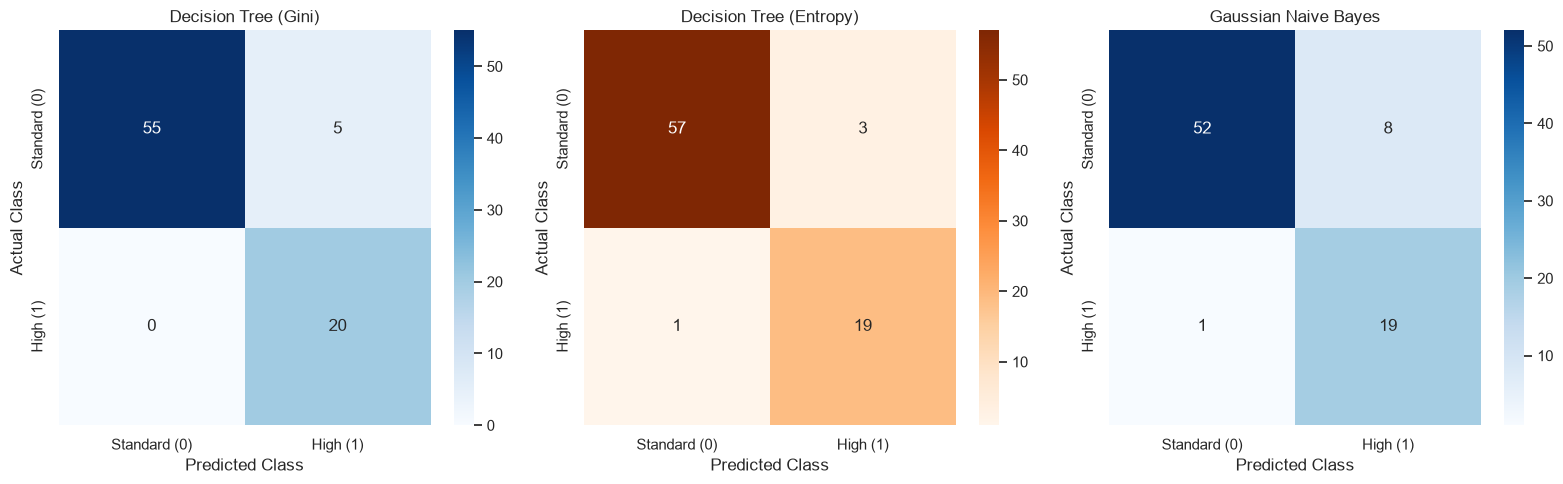

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

class_names = ["Standard (0)", "High (1)"]

for ax, (name, y_pred), color in zip(
    axes,
    predictions.items(),
    [BLUE, ORANGE, BLUE]
):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    cmap = "Blues" if color == BLUE else "Oranges"

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap=cmap,
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [39]:
for name, y_pred in predictions.items():
    print("\n" + "=" * 60)
    print(name)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["Standard", "High"],
            digits=4,
            zero_division=0
        )
    )


Decision Tree (Gini)
              precision    recall  f1-score   support

    Standard     1.0000    0.9167    0.9565        60
        High     0.8000    1.0000    0.8889        20

    accuracy                         0.9375        80
   macro avg     0.9000    0.9583    0.9227        80
weighted avg     0.9500    0.9375    0.9396        80


Decision Tree (Entropy)
              precision    recall  f1-score   support

    Standard     0.9828    0.9500    0.9661        60
        High     0.8636    0.9500    0.9048        20

    accuracy                         0.9500        80
   macro avg     0.9232    0.9500    0.9354        80
weighted avg     0.9530    0.9500    0.9508        80


Gaussian Naive Bayes
              precision    recall  f1-score   support

    Standard     0.9811    0.8667    0.9204        60
        High     0.7037    0.9500    0.8085        20

    accuracy                         0.8875        80
   macro avg     0.8424    0.9083    0.8644        80
weigh

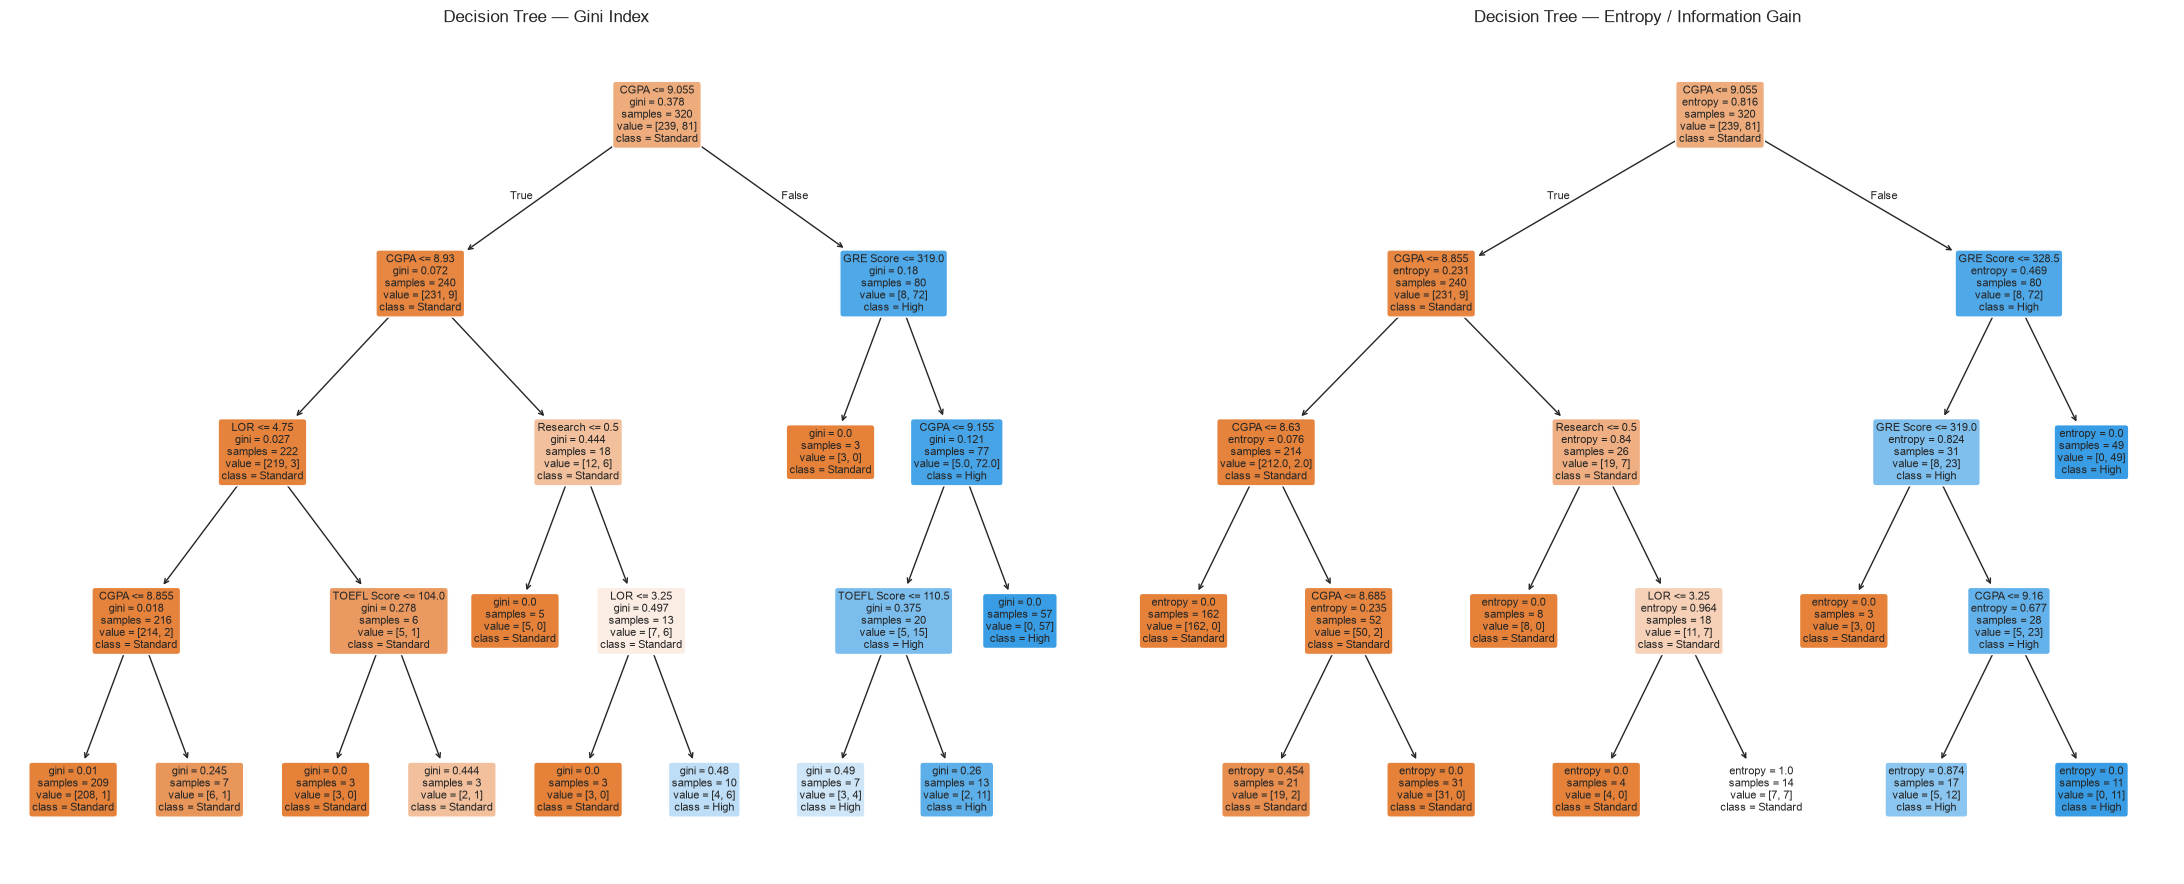

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(22, 9))

plot_tree(
    tree_gini,
    feature_names=X.columns.tolist(),
    class_names=["Standard", "High"],
    filled=True,
    rounded=True,
    fontsize=8,
    ax=axes[0]
)

axes[0].set_title("Decision Tree — Gini Index")

plot_tree(
    tree_entropy,
    feature_names=X.columns.tolist(),
    class_names=["Standard", "High"],
    filled=True,
    rounded=True,
    fontsize=8,
    ax=axes[1]
)

axes[1].set_title("Decision Tree — Entropy / Information Gain")

plt.tight_layout()
plt.show()

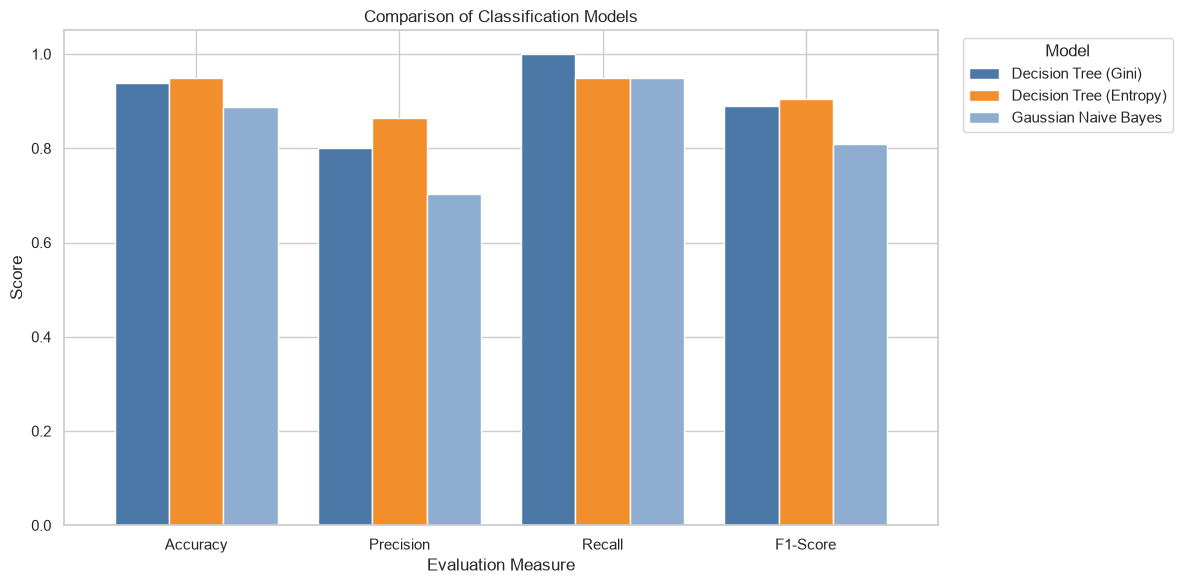

In [41]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

ax = results[metrics].T.plot(
    kind="bar",
    figsize=(12, 6),
    color=[
        BLUE,
        ORANGE,
        "#8EADD0"
    ],
    ylim=(0, 1.05),
    width=0.8
)

plt.title("Comparison of Classification Models")
plt.xlabel("Evaluation Measure")
plt.ylabel("Score")
plt.xticks(rotation=0)

plt.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [42]:
for metric in metrics:
    print(
        f"Best model by {metric}: "
        f"{results[metric].idxmax()} "
        f"({results[metric].max():.4f})"
    )

Best model by Accuracy: Decision Tree (Entropy) (0.9500)
Best model by Precision: Decision Tree (Entropy) (0.8636)
Best model by Recall: Decision Tree (Gini) (1.0000)
Best model by F1-Score: Decision Tree (Entropy) (0.9048)


In [43]:
overfitting_results = []

for name, model in models.items():
    train_accuracy = accuracy_score(
        y_train,
        model.predict(X_train)
    )

    test_accuracy = accuracy_score(
        y_test,
        model.predict(X_test)
    )

    overfitting_results.append({
        "Model": name,
        "Training Accuracy": train_accuracy,
        "Testing Accuracy": test_accuracy,
        "Accuracy Gap": train_accuracy - test_accuracy
    })

overfitting_df = pd.DataFrame(
    overfitting_results
).set_index("Model")

display(overfitting_df.round(4))

,Training Accuracy,Testing Accuracy,Accuracy Gap
Model,,,
Decision Tree (Gini),0.9625,0.9375,0.0250
Decision Tree (Entropy),0.9562,0.9500,0.0063
Gaussian Naive Bayes,0.9344,0.8875,0.0469


In [44]:
print("Gaussian Naive Bayes class order:")
print(naive_bayes.classes_)

print("\nLearned class priors:")
print(naive_bayes.class_prior_)

print("\nLearned feature means:")
display(
    pd.DataFrame(
        naive_bayes.theta_,
        index=["Standard", "High"],
        columns=X.columns
    )
)

print("\nLearned feature variances:")
display(
    pd.DataFrame(
        naive_bayes.var_,
        index=["Standard", "High"],
        columns=X.columns
    )
)

Gaussian Naive Bayes class order:
[0 1]

Learned class priors:
[0.746875 0.253125]

Learned feature means:


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
Standard,312.276151,104.974895,2.656904,3.060669,3.165272,8.341172,0.426778
High,329.802469,114.555556,4.333333,4.407407,4.240741,9.331605,0.938272



Learned feature variances:


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
Standard,85.112025,21.087236,0.827892,0.844646,0.641095,0.200154,0.244639
High,39.639994,12.740741,0.592593,0.259945,0.371056,0.076270,0.057918


In [ ]:
print("Enter the student's academic details:")

user_values = {}

for feature in X.columns:
    while True:
        try:
            value = float(input(f"Enter {feature}: "))
            user_values[feature] = value
            break
        except ValueError:
            print("Invalid input. Please enter a numeric value.")

# Create a DataFrame with the same feature order as training data
user_df = pd.DataFrame(
    [user_values],
    columns=X.columns
)

print("\nStudent input:")
display(user_df)

label_map = {
    0: "Standard Admission Chance",
    1: "High Admission Chance"
}

print("\nPredictions from all three models:")

for name, model in models.items():
    prediction = int(model.predict(user_df)[0])

    print(f"{name}: {label_map[prediction]}")

print(
    f"\nCalculated threshold: {threshold:.4f}"
)

Enter the student's academic details:


In [26]:
probability_rows = []

for name, model in models.items():
    probabilities = model.predict_proba(user_df)[0]

    class_probabilities = dict(
        zip(model.classes_, probabilities)
    )

    probability_rows.append({
        "Model": name,
        "Standard Probability": class_probabilities.get(0, 0),
        "High Probability": class_probabilities.get(1, 0)
    })

probability_df = pd.DataFrame(
    probability_rows
).set_index("Model")

display(probability_df.round(4))

,Standard Probability,High Probability
Model,,
Decision Tree (Gini),0.4,0.6
Decision Tree (Entropy),0.5,0.5
Gaussian Naive Bayes,1.0,0.0
